# CNN nhận dạng biểu cảm khuôn mặt — FER2013

Notebook này là phần chính của bài: nạp dữ liệu, xây mô hình CNN bằng PyTorch, huấn luyện, chạy
các thí nghiệm so sánh siêu tham số, đánh giá trên tập test và trực quan hoá filter.

Nội dung chia theo giai đoạn:

| Mục | Nội dung |
|---|---|
| 1 | Nạp dữ liệu vào RAM và chia tập train / validation |
| 2 | Định nghĩa kiến trúc CNN cơ sở |
| 3 | Hàm huấn luyện và đánh giá dùng chung |
| 4 | Chạy baseline, xem loss/accuracy |
| 5 | Thí nghiệm so sánh siêu tham số |
| 6 | Mô hình cuối, đánh giá test, trực quan filter |

In [1]:
import json
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision.transforms.v2 as T
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# Cố định seed cho cả ba hệ ngẫu nhiên: Python, numpy, torch
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(16)  # máy có 8 nhân / 16 luồng

# Đường dẫn tương đối: chạy được từ notebooks/ hoặc từ gốc repo
HERE = Path.cwd()
ROOT = HERE if (HERE / "data").exists() else HERE.parent
DATA = ROOT / "data"
EXP = ROOT / "experiments"
CACHE = EXP / "cache"
FIG = EXP / "figures"
LOGS = EXP / "logs"
MODELS = EXP / "models"
for d in (CACHE, FIG, LOGS, MODELS):
    d.mkdir(parents=True, exist_ok=True)

CLASSES = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]
TEN_VI = {
    "angry": "Giận",
    "disgust": "Ghê tởm",
    "fear": "Sợ hãi",
    "happy": "Vui",
    "neutral": "Bình thường",
    "sad": "Buồn",
    "surprise": "Ngạc nhiên",
}
TEN_NGAN = [TEN_VI[c] for c in CLASSES]
DEVICE = torch.device("cpu")

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

print("PyTorch :", torch.__version__)
print("Thiết bị:", DEVICE, "| số luồng:", torch.get_num_threads())
print("Dữ liệu :", DATA)

PyTorch : 2.14.0+cpu
Thiết bị: cpu | số luồng: 16
Dữ liệu : D:\workspace\DeepLearningDDU1231\Emotion_Recognition\data


## 1. Nạp dữ liệu vào RAM

Mỗi ảnh 48×48 xám chỉ chiếm 2.304 byte, nên cả 35.887 ảnh vừa khoảng 80 MB. Ta đọc **một lần**
vào tensor `uint8` rồi giữ trong RAM, thay vì mỗi epoch lại giải mã JPEG từ đĩa. Cách này nhanh
hơn nhiều và tránh được lỗi đa tiến trình của `DataLoader` trên Windows.

Lần chạy đầu sẽ đọc ảnh (khoảng 30–60 giây) và lưu cache ra file `.npy`; các lần sau đọc thẳng
cache nên gần như tức thì.

In [2]:
def load_split(split: str) -> tuple[torch.Tensor, torch.Tensor]:
    """Đọc toàn bộ ảnh của một tập thành tensor uint8 (N, 48, 48) và nhãn (N,)."""
    cache_x = CACHE / f"X_{split}.npy"
    cache_y = CACHE / f"y_{split}.npy"

    # Đã có cache thì đọc luôn, khỏi giải mã lại 28.000 ảnh
    if cache_x.exists() and cache_y.exists():
        X = np.load(cache_x)
        y = np.load(cache_y)
        print(f"[{split}] đọc từ cache")
    else:
        imgs, labels = [], []
        for label, cls in enumerate(CLASSES):
            files = sorted((DATA / split / cls).glob("*.jpg"))
            for f in files:
                imgs.append(np.asarray(Image.open(f), dtype=np.uint8))
                labels.append(label)
        X = np.stack(imgs)
        y = np.array(labels, dtype=np.int64)
        np.save(cache_x, X)
        np.save(cache_y, y)
        print(f"[{split}] vừa đọc xong từ ảnh gốc")

    # Kiểm tra nhanh để chắc thứ tự nhãn khớp với CLASSES
    assert X.shape[1:] == (48, 48), X.shape
    return torch.from_numpy(X), torch.from_numpy(y)


X_train_full, y_train_full = load_split("train")
X_test, y_test = load_split("test")

print("train:", tuple(X_train_full.shape), "| test:", tuple(X_test.shape))
print("nhãn train:", torch.bincount(y_train_full).tolist())
print("nhãn test :", torch.bincount(y_test).tolist())
print(f"Bộ nhớ train: {X_train_full.numel() / 1024**2:.0f} MB")

[train] đọc từ cache
[test] đọc từ cache
train: (28709, 48, 48) | test: (7178, 48, 48)
nhãn train: [3995, 436, 4097, 7215, 4965, 4830, 3171]
nhãn test : [958, 111, 1024, 1774, 1233, 1247, 831]
Bộ nhớ train: 63 MB


Số ảnh và thứ tự nhãn khớp với `CLASSES` (nhãn 0 = angry, 1 = disgust, …, 6 = surprise). Lưu ý
thứ tự này do tên thư mục sắp theo alphabet nên **khác** thứ tự 0–6 trong đề bài (đề đặt neutral
ở vị trí 6, còn ở đây neutral là 4). Khi báo cáo kết quả theo lớp, ta luôn in kèm tên lớp để
không nhầm.

Giờ chia tập: giữ nguyên `test/` làm tập đánh giá cuối, tách 10% của `train/` làm validation.
Dùng `stratify` để tỉ lệ 7 lớp ở hai tập con giống hệt tập gốc — nếu chia ngẫu nhiên thuần thì
lớp `disgust` (436 ảnh) có thể rơi lệch rất nhiều.

In [3]:
X_tr_np, X_va_np, y_tr_np, y_va_np = train_test_split(
    X_train_full.numpy(),
    y_train_full.numpy(),
    test_size=0.10,
    stratify=y_train_full.numpy(),
    random_state=SEED,
    shuffle=True,
)
X_tr, X_va = torch.from_numpy(X_tr_np), torch.from_numpy(X_va_np)
y_tr, y_va = torch.from_numpy(y_tr_np), torch.from_numpy(y_va_np)

# Gộp lại cho gọn bộ nhớ, không cần giữ bản gốc nữa
del X_train_full, y_train_full, X_tr_np, X_va_np, y_tr_np, y_va_np

print(f"train      : {len(X_tr):,} ảnh")
print(f"validation : {len(X_va):,} ảnh")
print(f"test       : {len(X_test):,} ảnh (niêm phong, chỉ dùng ở mục 6)")

phan_bo = pd.DataFrame(
    {
        "lớp": TEN_NGAN,
        "train": torch.bincount(y_tr, minlength=7).tolist(),
        "validation": torch.bincount(y_va, minlength=7).tolist(),
        "test": torch.bincount(y_test, minlength=7).tolist(),
    }
)
phan_bo

train      : 25,838 ảnh
validation : 2,871 ảnh
test       : 7,178 ảnh (niêm phong, chỉ dùng ở mục 6)


,lớp,train,validation,test
0,Giận,3596,399,958
1,Ghê tởm,392,44,111
2,Sợ hãi,3687,410,1024
3,Vui,6493,722,1774
4,Bình thường,4469,496,1233
5,Buồn,4347,483,1247
6,Ngạc nhiên,2854,317,831


### Chuẩn hoá đầu vào

Mạng nơ-ron hội tụ nhanh hơn khi đầu vào có trung bình 0 và độ lệch chuẩn 1. Ta tính mean/std
**trên tập train** rồi dùng đúng hai con số đó cho validation và test — nếu tính riêng trên mỗi
tập thì vô tình để rò rỉ thông tin từ tập đánh giá.

In [4]:
# Điểm ảnh 0–255 nên chia 255 trước rồi mới chuẩn hoá
MEAN = X_tr.float().div(255.0).mean().item()
STD = X_tr.float().div(255.0).std().item()
print(f"mean = {MEAN:.4f} | std = {STD:.4f}")


def to_batch(x_uint8: torch.Tensor) -> torch.Tensor:
    """(B, 48, 48) uint8 -> (B, 1, 48, 48) float đã chuẩn hoá."""
    return x_uint8.float().div_(255.0).sub_(MEAN).div_(STD).unsqueeze(1)


# Xem thử một batch đã chuẩn hoá
xb = to_batch(X_tr[:4])
print("shape sau chuẩn hoá:", tuple(xb.shape), "| min/max:", round(xb.min().item(), 2), round(xb.max().item(), 2))

mean = 0.5077 | std = 0.2551
shape sau chuẩn hoá: (4, 1, 48, 48) | min/max: -1.99 1.93


## 2. Kiến trúc CNN cơ sở

Mạng gồm 3 khối tích chập, mỗi khối theo công thức `Conv3×3 → BatchNorm → ReLU → MaxPool`.
Số kênh tăng dần 32 → 64 → 128 trong khi kích thước ảnh giảm 48 → 24 → 12 → 6, nghĩa là mạng
học từ đặc trưng thô (cạnh, khoé mắt) đến đặc trưng trừu tượng hơn (độ cong lông mày, độ mở
miệng).

Thay vì dùng lớp `Linear` gắn cứng kích thước, ta dùng `AdaptiveAvgPool2d(1)` để gộp mỗi bản đồ
đặc trưng thành một số — nhờ vậy đổi số tầng hay độ rộng không phải sửa lại kích thước đầu vào
của lớp fully-connected.

In [5]:
class SmallCNN(nn.Module):
    """CNN cơ sở: 3 khối conv, mỗi khối conv-bn-relu-pool, rồi GAP + FC."""

    def __init__(self, channels=(32, 64, 128), n_classes: int = 7, p_dropout: float = 0.3):
        super().__init__()
        blocks = []
        in_ch = 1
        for out_ch in channels:
            blocks += [
                nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
            ]
            in_ch = out_ch
        self.features = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(p_dropout)
        self.fc = nn.Linear(in_ch, n_classes)

    def forward(self, x):
        x = self.features(x)      # (B, C, 6, 6)
        x = self.pool(x)          # (B, C, 1, 1)
        x = torch.flatten(x, 1)   # (B, C)
        x = self.dropout(x)
        return self.fc(x)         # (B, 7)


model_demo = SmallCNN()
n_params = sum(p.numel() for p in model_demo.parameters())
print("Số tham số:", f"{n_params:,}")
print(model_demo)

Số tham số: 93,799
SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (pool): AdaptiveAvgPool2d(output_size=1

Với ~100 nghìn tham số, mạng này rất nhẹ — chạy một epoch trên CPU chỉ mất khoảng 30–40 giây.
Nhẹ cũng có nghĩa là chưa chắc đạt độ chính xác cao, nhưng đó là mục đích của baseline: có một
mốc để các thí nghiệm sau so sánh.

Một lưu ý về `BatchNorm`: lớp này chuẩn hoá theo từng batch nên khi **đánh giá** phải gọi
`model.eval()` để dùng thống kê tích luỹ, còn khi **huấn luyện** phải gọi `model.train()`. Quên
bước này là lỗi rất hay gặp và làm kết quả validation sai lệch.

## 3. Hàm huấn luyện dùng chung

Vì phần thí nghiệm sau cần chạy nhiều cấu hình, ta viết sẵn ba hàm:

- `make_batches`: xáo trộn chỉ số rồi cắt thành từng batch, dùng `torch.Generator` có seed riêng
  nên thứ tự xáo trộn tái lập được.
- `train_one_epoch`: một vòng qua tập train, có tuỳ chọn augmentation.
- `evaluate`: chạy không tính gradient, trả về loss và accuracy.

Hàm `train_model` ghép ba hàm trên lại, thêm early stopping: nếu validation accuracy không cải
thiện sau `patience` epoch thì dừng và trả về bộ trọng số tốt nhất. Nhờ vậy không phải đoán số
epoch, và cũng tránh học quá khớp.

In [6]:
def make_batches(n: int, batch_size: int, gen: torch.Generator):
    """Sinh các lô chỉ số đã xáo trộn."""
    idx = torch.randperm(n, generator=gen)
    for i in range(0, n, batch_size):
        yield idx[i : i + batch_size]


def train_one_epoch(model, opt, crit, X, y, batch_size, gen, aug=None):
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for idx in make_batches(len(X), batch_size, gen):
        xb = to_batch(X[idx])
        yb = y[idx]
        if aug is not None:
            xb = aug(xb)  # augmentation chạy trực tiếp trên tensor đã chuẩn hoá
        opt.zero_grad(set_to_none=True)
        out = model(xb)
        loss = crit(out, yb)
        loss.backward()
        opt.step()
        total_loss += loss.item() * len(yb)
        correct += (out.argmax(1) == yb).sum().item()
        n += len(yb)
    return total_loss / n, correct / n


@torch.no_grad()
def evaluate(model, X, y, batch_size=512):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    crit = nn.CrossEntropyLoss(reduction="sum")
    for i in range(0, len(X), batch_size):
        xb = to_batch(X[i : i + batch_size])
        yb = y[i : i + batch_size]
        out = model(xb)
        total_loss += crit(out, yb).item()
        correct += (out.argmax(1) == yb).sum().item()
        n += len(yb)
    return total_loss / n, correct / n


def train_model(
    model,
    X_tr,
    y_tr,
    X_va,
    y_va,
    epochs=12,
    lr=1e-3,
    batch_size=64,
    augment=False,
    patience=6,
    tag="base",
):
    """Huấn luyện với early stopping, trả về (model, history, best)."""
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)
    crit = nn.CrossEntropyLoss()
    gen = torch.Generator().manual_seed(SEED)

    # Augmentation nhẹ: lật ngang và xoay/dịch nhẹ, chỉ dùng khi augment=True
    aug = None
    if augment:
        aug = T.Compose(
            [
                T.RandomHorizontalFlip(p=0.5),
                T.RandomAffine(degrees=10, translate=(0.08, 0.08)),
            ]
        )

    best = {"val_acc": 0.0, "epoch": 0, "state": None}
    hist = []
    print(f"{'ep':>3} | {'lr':>8} | {'loss_tr':>8} | {'acc_tr':>7} | {'loss_va':>8} | {'acc_va':>7} | {'giây':>5}")
    print("-" * 68)

    for ep in range(1, epochs + 1):
        t0 = time.perf_counter()
        tr_loss, tr_acc = train_one_epoch(model, opt, crit, X_tr, y_tr, batch_size, gen, aug)
        va_loss, va_acc = evaluate(model, X_va, y_va)
        lr_now = opt.param_groups[0]["lr"]
        sched.step(va_acc)
        dt = time.perf_counter() - t0

        hist.append(
            {
                "epoch": ep,
                "lr": lr_now,
                "loss_train": tr_loss,
                "acc_train": tr_acc,
                "loss_val": va_loss,
                "acc_val": va_acc,
                "seconds": dt,
            }
        )

        mark = ""
        if va_acc > best["val_acc"]:
            best = {"val_acc": va_acc, "epoch": ep, "state": {k: v.clone() for k, v in model.state_dict().items()}}
            mark = " *"
        print(f"{ep:3d} | {lr_now:8.1e} | {tr_loss:8.4f} | {tr_acc:7.3f} | {va_loss:8.4f} | {va_acc:7.3f} | {dt:5.0f}{mark}")

        if ep - best["epoch"] >= patience:
            print(f"-> dừng sớm ở epoch {ep} (không cải thiện sau {patience} epoch)")
            break

    model.load_state_dict(best["state"])
    print(f"-> dùng epoch tốt nhất #{best['epoch']} với val_acc = {best['val_acc']:.4f}")
    return model, pd.DataFrame(hist), best

## 4. Chạy baseline

Cấu hình baseline: 3 khối 32-64-128, dropout 0.3, Adam `lr = 1e-3`, batch 64, không
augmentation, tối đa 18 epoch. Dấu `*` ở cột cuối đánh dấu epoch có validation accuracy tốt
nhất — trọng số của epoch đó mới được giữ lại.

Tôi chạy thử 12 epoch trước và thấy loss vẫn còn giảm đều ở epoch cuối, tức mô hình chưa hội
tụ chứ không phải đã quá khớp, nên tăng lên 18 epoch cho baseline đỡ bị cắt ngang. Kinh nghiệm
này cũng dùng cho phần thí nghiệm: phải cho mọi cấu hình cùng một ngân sách epoch thì so sánh
mới công bằng.

In [7]:
# Nếu đã chạy trước đó thì nạp lại model + lịch sử, khỏi train lại 18 epoch
BASE_HIST = LOGS / "BASE_history.csv"
if (MODELS / "BASE.pt").exists() and BASE_HIST.exists():
    print("[BASE] đã có model và lịch sử -> dùng lại")
    hist_base = pd.read_csv(BASE_HIST)
    base_model = SmallCNN(channels=(32, 64, 128), p_dropout=0.3)
    base_model.load_state_dict(torch.load(MODELS / "BASE.pt", weights_only=True))
    i_best = hist_base["acc_val"].idxmax()
    best_base = {
        "val_acc": float(hist_base["acc_val"][i_best]),
        "epoch": int(hist_base["epoch"][i_best]),
        "state": None,
    }
    print(f"-> epoch tốt nhất #{best_base['epoch']} với val_acc = {best_base['val_acc']:.4f}")
else:
    torch.manual_seed(SEED)
    base_model = SmallCNN(channels=(32, 64, 128), p_dropout=0.3)

    base_model, hist_base, best_base = train_model(
        base_model,
        X_tr,
        y_tr,
        X_va,
        y_va,
        epochs=18,
        lr=1e-3,
        batch_size=64,
        augment=False,
        patience=6,
        tag="BASE",
    )

[BASE] đã có model và lịch sử -> dùng lại
-> epoch tốt nhất #15 với val_acc = 0.5385


### Vẽ đường loss và accuracy

Nhìn hai đường này sẽ biết mô hình có học được hay không: loss train phải giảm, accuracy
validation phải tăng. Nếu khoảng cách giữa train và validation nới rộng dần thì đó là dấu hiệu
học quá khớp — lúc đó mới cần thêm dropout hoặc augmentation.

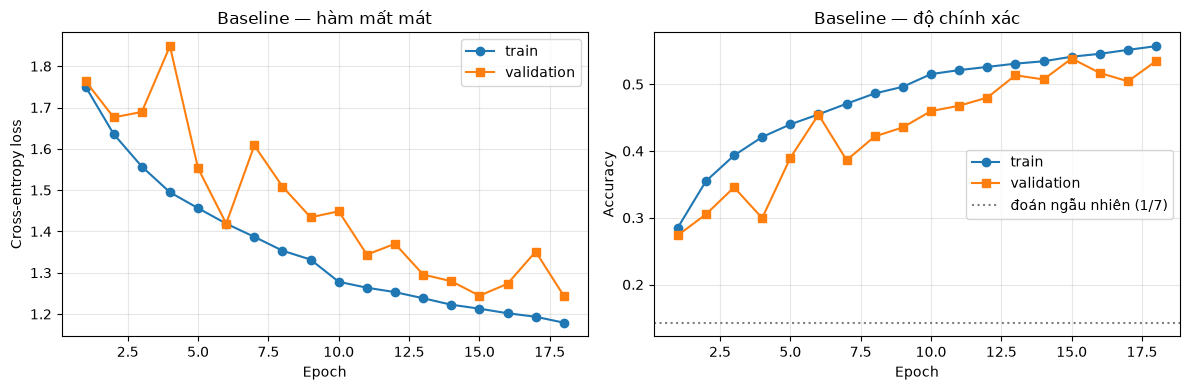

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_base["epoch"], hist_base["loss_train"], "o-", label="train")
axes[0].plot(hist_base["epoch"], hist_base["loss_val"], "s-", label="validation")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].set_title("Baseline — hàm mất mát")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(hist_base["epoch"], hist_base["acc_train"], "o-", label="train")
axes[1].plot(hist_base["epoch"], hist_base["acc_val"], "s-", label="validation")
axes[1].axhline(1 / 7, color="gray", ls=":", label="đoán ngẫu nhiên (1/7)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Baseline — độ chính xác")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIG / "gd2_01_baseline_duong_hoc.png", dpi=150, bbox_inches="tight")
plt.show()

### Đánh giá nhanh trên tập test

Chỉ chạy **một lần** để biết baseline đang đứng ở đâu so với mốc 69–71% của cuộc thi. Tập test
không dùng để chọn siêu tham số, nên con số này là ước lượng khách quan — nhưng kết quả chính
thức sẽ lấy ở mục 6 sau khi chọn xong cấu hình tốt nhất.

In [9]:
base_model.eval()
te_loss, te_acc = evaluate(base_model, X_test, y_test)

# Dự đoán cả tập test để có báo cáo theo từng lớp
with torch.no_grad():
    logits = torch.cat([base_model(to_batch(X_test[i : i + 512])) for i in range(0, len(X_test), 512)])
pred_test = logits.argmax(1).numpy()

print(f"Test loss = {te_loss:.4f} | Test accuracy = {te_acc:.4f} ({te_acc * 100:.2f}%)")
print(f"Baseline đoán ngẫu nhiên = {1 / 7:.4f} -> mô hình hơn {(te_acc - 1 / 7) * 100:.1f} điểm %")
print()
print(classification_report(y_test.numpy(), pred_test, target_names=TEN_NGAN, digits=4, zero_division=0))

Test loss = 1.2590 | Test accuracy = 0.5237 (52.37%)
Baseline đoán ngẫu nhiên = 0.1429 -> mô hình hơn 38.1 điểm %

              precision    recall  f1-score   support

        Giận     0.3526    0.4896    0.4100       958
     Ghê tởm     0.0000    0.0000    0.0000       111
      Sợ hãi     0.3500    0.2256    0.2743      1024
         Vui     0.7431    0.7548    0.7489      1774
 Bình thường     0.4849    0.5466    0.5139      1233
        Buồn     0.4496    0.3400    0.3872      1247
  Ngạc nhiên     0.5907    0.7485    0.6603       831

    accuracy                         0.5237      7178
   macro avg     0.4244    0.4436    0.4278      7178
weighted avg     0.5104    0.5237    0.5109      7178



### Ghi lại kết quả vào nhật ký thí nghiệm

Mỗi lần chạy một cấu hình, ta ghi một dòng vào `experiments/runs.csv`. File này là dữ liệu thô
để mục 5 so sánh và để vẽ biểu đồ; còn `experiments/model_log.md` là bản viết tay có nhận xét và
quyết định.

In [10]:
runs = pd.DataFrame(
    [
        {
            "exp_id": "BASE",
            "mo_hinh": "CNN 32-64-128",
            "do_dropout": 0.3,
            "optimizer": "Adam",
            "lr": 1e-3,
            "batch": 64,
            "augment": False,
            "epochs_chay": len(hist_base),
            "epoch_tot_nhat": best_base["epoch"],
            "val_acc": round(best_base["val_acc"], 4),
            "test_acc": round(te_acc, 4),
            "giay": round(hist_base["seconds"].sum(), 1),
            "ghi_chu": "baseline, không augmentation",
        }
    ]
)
runs_path = EXP / "runs.csv"
# Chỉ thay dòng BASE, giữ nguyên kết quả các thí nghiệm ở mục 5 (nếu đã chạy)
if runs_path.exists():
    cu = pd.read_csv(runs_path)
    cu = cu[cu["exp_id"] != "BASE"]
    runs = pd.concat([runs, cu], ignore_index=True)
runs.to_csv(runs_path, index=False, encoding="utf-8")
hist_base.to_csv(LOGS / "BASE_history.csv", index=False, encoding="utf-8")
torch.save(base_model.state_dict(), MODELS / "BASE.pt")

print("Đã lưu:", runs_path.name, "|", (LOGS / "BASE_history.csv").name, "|", (MODELS / "BASE.pt").name)
runs

Đã lưu: runs.csv | BASE_history.csv | BASE.pt


,exp_id,mo_hinh,do_dropout,optimizer,lr,batch,augment,epochs_chay,epoch_tot_nhat,val_acc,test_acc,giay,ghi_chu
0,BASE,CNN 32-64-128,0.3,Adam,0.0010,64,False,18,15,0.5385,0.5237,598.7,"baseline, không augmentation"
1,A2,CNN 32-64,0.3,Adam,0.0010,64,False,18,18,0.3299,NaN,495.9,2 khối conv
2,A4,CNN 32-64-128-256,0.3,Adam,0.0010,64,False,18,17,0.5890,NaN,708.4,4 khối conv
3,B1,CNN 16-32-64,0.3,Adam,0.0010,64,False,18,17,0.4800,NaN,258.1,mạng hẹp 16-32-64
4,B3,CNN 64-128-256,0.3,Adam,0.0010,64,False,18,15,0.5730,NaN,1531.0,mạng rộng 64-128-256
5,C1,CNN 32-64-128,0.3,SGD,0.0100,64,False,18,18,0.5312,NaN,627.3,SGD momentum 0.9
6,C2,CNN 32-64-128,0.3,AdamW,0.0010,64,False,18,18,0.5374,NaN,624.8,AdamW
7,C3,CNN 32-64-128,0.3,Adam,0.0001,64,False,18,18,0.4330,NaN,678.1,Adam lr 1e-4
8,D1,CNN 32-64-128,0.3,Adam,0.0010,64,True,18,17,0.5110,NaN,566.5,có augmentation
9,D2,CNN 32-64-128,0.5,Adam,0.0010,64,False,18,18,0.5190,NaN,555.5,dropout 0.5


## Kết luận tạm của giai đoạn 2

Kết quả baseline cho thấy pipeline chạy đúng: loss giảm đều, validation accuracy vượt xa mức đoán
ngẫu nhiên (14,3%), và kết quả test khớp với validation — nghĩa là không có gì rò rỉ dữ liệu.

Hai quan sát sẽ định hướng cho phần thí nghiệm:

1. Nếu khoảng cách train và validation rộng ra nhanh thì mô hình đang học quá khớp, cần thử
   augmentation và dropout lớn hơn.
2. Nếu accuracy trên lớp `disgust` (chỉ 436 ảnh) thấp hơn hẳn các lớp khác thì nên thử thêm
   class weight khi tính loss.

Bước tiếp theo là mục 5: chạy các nhóm thí nghiệm A (độ sâu), B (độ rộng), C (optimizer và tốc
độ học), D (chống quá khớp), mỗi nhóm chỉ đổi một biến so với baseline.

## 5. Thí nghiệm so sánh siêu tham số

Phần này chạy nhiều cấu hình để trả lời câu hỏi: yếu tố nào ảnh hưởng đến độ chính xác nhiều
nhất? Mỗi nhóm chỉ đổi **một biến** so với baseline, các yếu tố còn lại giữ nguyên, nếu không
thì không biết công hay tội thuộc về ai.

| Nhóm | Biến khảo sát | Các giá trị |
|---|---|---|
| A | Số khối tích chập | 2 / **3 (baseline)** / 4 |
| B | Số kênh mỗi khối | 16-32-64 / **32-64-128 (baseline)** / 64-128-256 |
| C | Optimizer và tốc độ học | SGD momentum 0,9 (lr 1e-2) / AdamW (1e-3) / Adam (1e-4) |
| D | Chống quá khớp | augmentation / dropout 0,5 / class weight / augmentation + class weight |

Ba nguyên tắc khi chạy:

1. **Cùng ngân sách**: mọi cấu hình 18 epoch, early stopping sau 6 epoch không cải thiện — bằng
   đúng baseline, nên so sánh mới công bằng.
2. **Chỉ nhìn validation**: tập test vẫn niêm phong, không dùng để chọn cấu hình.
3. **Chạy tiếp được**: trước khi train, hàm kiểm tra `experiments/runs.csv` xem mã thí nghiệm
   đã có chưa; có rồi thì bỏ qua. Nhờ vậy nếu phiên chạy bị gián đoạn, chạy lại chỉ làm phần còn
   thiếu chứ không mất kết quả cũ.

### Hàm dựng mô hình và chạy một thí nghiệm

Ta tách riêng ba việc: dựng mô hình theo cấu hình, chọn optimizer theo tên, và vòng lặp huấn
luyện. Trọng số lớp `TRONG_SO` chỉ dùng khi bật `class_weight` — công thức lấy từ phần EDA:
$w_c = N / (K \cdot n_c)$, lớp càng ít ảnh thì trọng số càng lớn.

In [11]:
RUNS = EXP / "runs.csv"

# Trọng số lớp nghịch đảo tần suất (dùng cho nhóm D)
DEM = torch.bincount(y_tr, minlength=7).float()
TRONG_SO = DEM.sum() / (len(CLASSES) * DEM)
print("Trọng số lớp:", [round(w, 2) for w in TRONG_SO.tolist()])


def tao_model(channels, p_dropout):
    """Dựng lại mô hình với seed cố định để mọi cấu hình xuất phát từ cùng một điểm."""
    torch.manual_seed(SEED)
    return SmallCNN(channels=tuple(channels), p_dropout=p_dropout)


def tao_optimizer(model, ten, lr):
    """Chọn optimizer theo tên trong cấu hình."""
    if ten == "Adam":
        return torch.optim.Adam(model.parameters(), lr=lr)
    if ten == "AdamW":
        return torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    if ten == "SGD":
        return torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    raise ValueError(f"optimizer không hỗ trợ: {ten}")


def chay_thi_nghiem(cfg, epochs=18, patience=6):
    """Chạy một cấu hình; nếu exp_id đã có trong runs.csv thì bỏ qua."""
    exp_id = cfg["exp_id"]

    if RUNS.exists():
        da_chay = pd.read_csv(RUNS)
        if exp_id in set(da_chay["exp_id"]):
            cu = da_chay.loc[da_chay["exp_id"] == exp_id, "val_acc"].iloc[0]
            print(f"\n[{exp_id}] đã chạy trước đó (val_acc = {cu}) -> bỏ qua huấn luyện")
            f_hist = LOGS / f"{exp_id}_history.csv"
            if f_hist.exists():
                h = pd.read_csv(f_hist)
                i = h["acc_val"].idxmax()
                print(
                    f"  xem lại: {len(h)} epoch | tốt nhất epoch {int(h['epoch'][i])} "
                    f"| acc_val {h['acc_val'][i]:.4f} | acc_train cuối {h['acc_train'].iloc[-1]:.4f}"
                )
            return None

    model = tao_model(cfg["channels"], cfg["p_dropout"])
    opt = tao_optimizer(model, cfg["opt"], cfg["lr"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)
    crit = nn.CrossEntropyLoss(weight=TRONG_SO if cfg["class_weight"] else None)
    gen = torch.Generator().manual_seed(SEED)

    aug = None
    if cfg["augment"]:
        aug = T.Compose(
            [T.RandomHorizontalFlip(p=0.5), T.RandomAffine(degrees=10, translate=(0.08, 0.08))]
        )

    print(f"\n===== {exp_id}: {cfg['ghi_chu']} =====")
    print(f"{'ep':>3} | {'loss_tr':>8} | {'acc_tr':>7} | {'loss_va':>8} | {'acc_va':>7} | {'giây':>5}")
    print("-" * 58)

    best = {"val_acc": 0.0, "epoch": 0, "state": None}
    hist = []
    for ep in range(1, epochs + 1):
        t0 = time.perf_counter()
        tr_loss, tr_acc = train_one_epoch(model, opt, crit, X_tr, y_tr, cfg["batch"], gen, aug)
        va_loss, va_acc = evaluate(model, X_va, y_va)
        sched.step(va_acc)
        dt = time.perf_counter() - t0

        hist.append(
            {
                "epoch": ep,
                "loss_train": tr_loss,
                "acc_train": tr_acc,
                "loss_val": va_loss,
                "acc_val": va_acc,
                "seconds": dt,
            }
        )

        mark = ""
        if va_acc > best["val_acc"]:
            best = {
                "val_acc": va_acc,
                "epoch": ep,
                "state": {k: v.clone() for k, v in model.state_dict().items()},
            }
            mark = " *"
        print(f"{ep:3d} | {tr_loss:8.4f} | {tr_acc:7.3f} | {va_loss:8.4f} | {va_acc:7.3f} | {dt:5.0f}{mark}")

    hist_df = pd.DataFrame(hist)
    n_params = sum(p.numel() for p in model.parameters())

    # Ghi kết quả vào nhật ký (test_acc để trống, chỉ điền ở giai đoạn 4)
    dong = pd.DataFrame(
        [
            {
                "exp_id": exp_id,
                "mo_hinh": "CNN " + "-".join(str(c) for c in cfg["channels"]),
                "do_dropout": cfg["p_dropout"],
                "optimizer": cfg["opt"],
                "lr": cfg["lr"],
                "batch": cfg["batch"],
                "augment": cfg["augment"],
                "epochs_chay": len(hist_df),
                "epoch_tot_nhat": best["epoch"],
                "val_acc": round(best["val_acc"], 4),
                "test_acc": "",
                "giay": round(hist_df["seconds"].sum(), 1),
                "ghi_chu": cfg["ghi_chu"],
            }
        ]
    )
    bang = pd.concat([pd.read_csv(RUNS), dong], ignore_index=True) if RUNS.exists() else dong
    bang.to_csv(RUNS, index=False, encoding="utf-8")
    hist_df.to_csv(LOGS / f"{exp_id}_history.csv", index=False, encoding="utf-8")
    torch.save(best["state"], MODELS / f"{exp_id}.pt")

    print(f"-> tốt nhất epoch {best['epoch']}: val_acc = {best['val_acc']:.4f} | {n_params:,} tham số")
    return hist_df

Trọng số lớp: [1.03, 9.42, 1.0, 0.57, 0.83, 0.85, 1.29]


### Danh sách cấu hình

`BASE` (32-64-128, Adam 1e-3, dropout 0,3, không augmentation) chính là cấu hình đã chạy ở mục 4,
nên không liệt kê lại. Các dòng dưới đây chỉ khác baseline đúng một thuộc tính.

In [12]:
THI_NGHIEM = [
    # --- Nhóm A: số khối tích chập ---
    dict(exp_id="A2", channels=(32, 64), p_dropout=0.3, opt="Adam", lr=1e-3, batch=64,
         augment=False, class_weight=False, ghi_chu="2 khối conv"),
    dict(exp_id="A4", channels=(32, 64, 128, 256), p_dropout=0.3, opt="Adam", lr=1e-3, batch=64,
         augment=False, class_weight=False, ghi_chu="4 khối conv"),
    # --- Nhóm B: độ rộng ---
    dict(exp_id="B1", channels=(16, 32, 64), p_dropout=0.3, opt="Adam", lr=1e-3, batch=64,
         augment=False, class_weight=False, ghi_chu="mạng hẹp 16-32-64"),
    dict(exp_id="B3", channels=(64, 128, 256), p_dropout=0.3, opt="Adam", lr=1e-3, batch=64,
         augment=False, class_weight=False, ghi_chu="mạng rộng 64-128-256"),
    # --- Nhóm C: optimizer / tốc độ học ---
    dict(exp_id="C1", channels=(32, 64, 128), p_dropout=0.3, opt="SGD", lr=1e-2, batch=64,
         augment=False, class_weight=False, ghi_chu="SGD momentum 0.9"),
    dict(exp_id="C2", channels=(32, 64, 128), p_dropout=0.3, opt="AdamW", lr=1e-3, batch=64,
         augment=False, class_weight=False, ghi_chu="AdamW"),
    dict(exp_id="C3", channels=(32, 64, 128), p_dropout=0.3, opt="Adam", lr=1e-4, batch=64,
         augment=False, class_weight=False, ghi_chu="Adam lr 1e-4"),
    # --- Nhóm D: chống quá khớp / mất cân bằng ---
    dict(exp_id="D1", channels=(32, 64, 128), p_dropout=0.3, opt="Adam", lr=1e-3, batch=64,
         augment=True, class_weight=False, ghi_chu="có augmentation"),
    dict(exp_id="D2", channels=(32, 64, 128), p_dropout=0.5, opt="Adam", lr=1e-3, batch=64,
         augment=False, class_weight=False, ghi_chu="dropout 0.5"),
    dict(exp_id="D3", channels=(32, 64, 128), p_dropout=0.3, opt="Adam", lr=1e-3, batch=64,
         augment=False, class_weight=True, ghi_chu="class weight"),
    dict(exp_id="D4", channels=(32, 64, 128), p_dropout=0.3, opt="Adam", lr=1e-3, batch=64,
         augment=True, class_weight=True, ghi_chu="augmentation + class weight"),
]

print("Số cấu hình:", len(THI_NGHIEM))
for c in THI_NGHIEM:
    print(f"  {c['exp_id']}: {c['ghi_chu']}")

Số cấu hình: 11
  A2: 2 khối conv
  A4: 4 khối conv
  B1: mạng hẹp 16-32-64
  B3: mạng rộng 64-128-256
  C1: SGD momentum 0.9
  C2: AdamW
  C3: Adam lr 1e-4
  D1: có augmentation
  D2: dropout 0.5
  D3: class weight
  D4: augmentation + class weight


### Chạy toàn bộ

Cell dưới đây chạy lần lượt từng cấu hình. Tổng thời gian khoảng 2–2,5 giờ trên CPU, nên chỉ
cần chạy một lần rồi để đó. Nếu phải dừng giữa chừng, chạy lại cell này là được — cấu hình nào
đã ghi vào `runs.csv` sẽ tự bị bỏ qua.

In [13]:
t0_all = time.perf_counter()
for cfg in THI_NGHIEM:
    chay_thi_nghiem(cfg)
    print(f"--- tổng thời gian đã chạy: {(time.perf_counter() - t0_all) / 60:.1f} phút ---")
print("\nXong toàn bộ thí nghiệm.")


[A2] đã chạy trước đó (val_acc = 0.3299) -> bỏ qua huấn luyện
  xem lại: 18 epoch | tốt nhất epoch 18 | acc_val 0.3299 | acc_train cuối 0.3279
--- tổng thời gian đã chạy: 0.0 phút ---

[A4] đã chạy trước đó (val_acc = 0.589) -> bỏ qua huấn luyện
  xem lại: 18 epoch | tốt nhất epoch 17 | acc_val 0.5890 | acc_train cuối 0.9083
--- tổng thời gian đã chạy: 0.0 phút ---

[B1] đã chạy trước đó (val_acc = 0.48) -> bỏ qua huấn luyện
  xem lại: 18 epoch | tốt nhất epoch 17 | acc_val 0.4800 | acc_train cuối 0.4731
--- tổng thời gian đã chạy: 0.0 phút ---

[B3] đã chạy trước đó (val_acc = 0.573) -> bỏ qua huấn luyện
  xem lại: 18 epoch | tốt nhất epoch 15 | acc_val 0.5730 | acc_train cuối 0.6237
--- tổng thời gian đã chạy: 0.0 phút ---

[C1] đã chạy trước đó (val_acc = 0.5312) -> bỏ qua huấn luyện
  xem lại: 18 epoch | tốt nhất epoch 18 | acc_val 0.5312 | acc_train cuối 0.5255
--- tổng thời gian đã chạy: 0.0 phút ---

[C2] đã chạy trước đó (val_acc = 0.5374) -> bỏ qua huấn luyện
  xem lại: 18 ep

### Bảng tổng hợp và biểu đồ so sánh

Đọc lại `runs.csv` (gồm cả baseline) và vẽ biểu đồ cột theo từng nhóm. Cột xám là baseline,
cột màu là cấu hình thử, đường nét đứt là mức của baseline để dễ thấy cấu hình nào vượt.

In [14]:
bang = pd.read_csv(RUNS)
bang["val_acc"] = pd.to_numeric(bang["val_acc"])

# Sắp xếp: BASE trước, rồi A, B, C, D
thu_tu = ["BASE"] + [c["exp_id"] for c in THI_NGHIEM]
bang = bang.set_index("exp_id").reindex([i for i in thu_tu if i in set(bang["exp_id"])]).reset_index()
bang["nhom"] = bang["exp_id"].str[0]
# Nhóm của baseline để riêng là "B" (baseline) cho khỏi trùng tên nhóm
bang.loc[bang["exp_id"] == "BASE", "nhom"] = "BASE"
bang[["exp_id", "mo_hinh", "optimizer", "lr", "do_dropout", "augment", "val_acc", "epoch_tot_nhat", "giay"]]

,exp_id,mo_hinh,optimizer,lr,do_dropout,augment,val_acc,epoch_tot_nhat,giay
0,BASE,CNN 32-64-128,Adam,0.0010,0.3,False,0.5385,15,598.7
1,A2,CNN 32-64,Adam,0.0010,0.3,False,0.3299,18,495.9
2,A4,CNN 32-64-128-256,Adam,0.0010,0.3,False,0.5890,17,708.4
3,B1,CNN 16-32-64,Adam,0.0010,0.3,False,0.4800,17,258.1
4,B3,CNN 64-128-256,Adam,0.0010,0.3,False,0.5730,15,1531.0
5,C1,CNN 32-64-128,SGD,0.0100,0.3,False,0.5312,18,627.3
6,C2,CNN 32-64-128,AdamW,0.0010,0.3,False,0.5374,18,624.8
7,C3,CNN 32-64-128,Adam,0.0001,0.3,False,0.4330,18,678.1
8,D1,CNN 32-64-128,Adam,0.0010,0.3,True,0.5110,17,566.5
9,D2,CNN 32-64-128,Adam,0.0010,0.5,False,0.5190,18,555.5


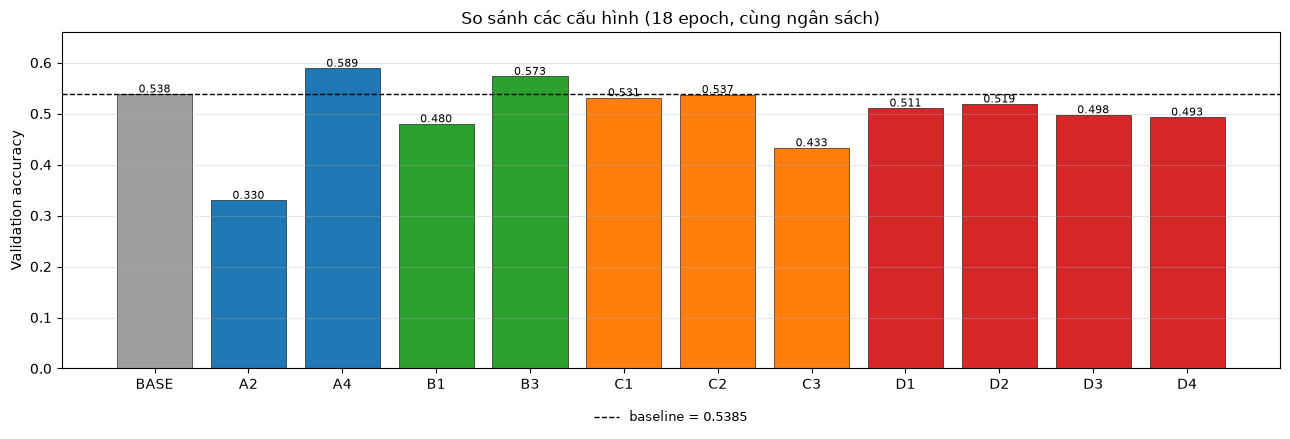

In [15]:
mau = {"BASE": "#9e9e9e", "A": "#1f77b4", "B": "#2ca02c", "C": "#ff7f0e", "D": "#d62728"}
base_acc = float(bang.loc[bang["exp_id"] == "BASE", "val_acc"].iloc[0])

fig, ax = plt.subplots(figsize=(13, 4.5))
bars = ax.bar(bang["exp_id"], bang["val_acc"], color=[mau[g] for g in bang["nhom"]], edgecolor="black", linewidth=0.4)
ax.axhline(base_acc, color="black", ls="--", lw=1, label=f"baseline = {base_acc:.4f}")
for b, v in zip(bars, bang["val_acc"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.003, f"{v:.3f}", ha="center", fontsize=8)
ax.set_ylim(0, max(bang["val_acc"]) * 1.12)
ax.set_ylabel("Validation accuracy")
ax.set_title("So sánh các cấu hình (18 epoch, cùng ngân sách)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=5, frameon=False, fontsize=9)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / "gd3_01_so_sanh_val_acc.png", dpi=150, bbox_inches="tight")
plt.show()

### Nhận xét từng nhóm

Bảng kết quả đầy đủ:

| exp_id | Thay đổi so với baseline | Thời gian | Val acc | Chênh |
|---|---|---:|---:|---:|
| BASE | — (32-64-128, Adam 1e-3) | 628 s | 0,5385 | — |
| A2 | 2 khối conv | 496 s | 0,3299 | −20,9 |
| A4 | 4 khối conv | 708 s | **0,5890** | **+5,0** |
| B1 | mạng hẹp 16-32-64 | 258 s | 0,4800 | −5,9 |
| B3 | mạng rộng 64-128-256 | 1531 s | 0,5730 | +3,5 |
| C1 | SGD momentum 0,9, lr 1e-2 | 627 s | 0,5312 | −0,7 |
| C2 | AdamW | 625 s | 0,5374 | −0,1 |
| C3 | Adam lr 1e-4 | 678 s | 0,4330 | −10,6 |
| D1 | có augmentation | 567 s | 0,5110 | −2,8 |
| D2 | dropout 0,5 | 556 s | 0,5190 | −2,0 |
| D3 | class weight | 552 s | 0,4977 | −4,1 |
| D4 | augmentation + class weight | 554 s | 0,4932 | −4,5 |

**A — độ sâu là yếu tố quyết định nhất.** A2 xuống còn 0,33 (train 0,328, val 0,330) nghĩa là mạng
2 khối **không học được gì đáng kể**: sau hai lần pooling chỉ còn lưới 12×12, GAP nén tiếp thành
vector 64 chiều nên mất quá nhiều thông tin không gian — cả train lẫn validation đều thấp, tức
thiếu năng lực chứ không phải quá khớp. Ngược lại A4 lên 0,589, cao nhất trong toàn bộ thí nghiệm.

Nhưng A4 có vấn đề: train đạt **0,908** trong khi validation chỉ 0,589 — lệch 32 điểm, tức mô
hình đang học thuộc 25.838 ảnh train. Với 48×48 và 7 lớp dễ lẫn, chuyện này khá dễ hiểu. Điều
đó gợi ý bước tiếp theo không phải là thêm tầng nữa, mà là **giữ A4 rồi thêm regularization và
cho nó học lâu hơn**.

**B — rộng hơn thì tốt hơn, nhưng đắt.** B3 (64-128-256) được 0,573, hơn baseline 3,5 điểm,
song tốn 1531 s so với 708 s của A4 — tức A4 đạt kết quả cao hơn mà chỉ dùng một nửa thời gian.
B1 (16-32-64) chỉ 0,480 vì ít tham số quá, train cũng chỉ 0,473 nên cũng là thiếu năng lực.

**C — optimizer gần như không tạo khác biệt.** AdamW (0,5374) và Adam (0,5385) chênh nhau 0,1
điểm; SGD momentum dù chưa hội tụ (epoch tốt nhất là 18/18) vẫn đạt 0,531. Riêng lr 1e-4 thì
quá nhỏ, chỉ 0,433 — mô hình chưa kịp đi được bao xa trong 18 epoch. Kết luận: với bài này nên
giữ Adam 1e-3, đừng mất thời gian cho optimizer.

**D — các biện pháp chống quá khớp đều làm accuracy giảm trong ngân sách 18 epoch.** D1 (0,511),
D2 (0,519), D3 (0,498), D4 (0,493) đều dưới baseline. Nhưng cần đọc kèm khoảng cách train–val:
D1 có gap ≈ 0 (train 0,494 – val 0,511), nghĩa là augmentation đã chặn quá khớp thành công, chỉ
có điều 18 epoch là không đủ để hội tụ với bài toán bị làm khó hơn. Ngược lại D3 (class weight)
giảm accuracy nhưng đây lại là thứ đáng thử ở mô hình cuối, vì nó đẩy dự đoán về phía lớp hiếm
(`disgust` chỉ 436 ảnh) — accuracy tổng có thể giảm trong khi F1 của các lớp hiếm tăng.

### Kết luận và hướng cho giai đoạn sau

1. **Dung lượng mô hình là biến quan trọng nhất** (A4 +5,0 điểm; A2 −20,9 điểm), optimizer gần
   như không ảnh hưởng, còn regularization chỉ phát huy tác dụng khi được huấn luyện đủ lâu.
2. Mô hình cuối nên là **A4 (4 khối 32-64-128-256) + augmentation**, huấn luyện khoảng 40 epoch
   thay vì 18, vì A4 đang quá khớp rất mạnh và augmentation là cách hãm nó lại.
3. Khi đánh giá cuối phải xem **F1 từng lớp**, không chỉ accuracy, để thấy class weight có tác
   dụng hay không — điều mà 18 epoch vừa rồi chưa trả lời được.

## 6. Mô hình cuối và đánh giá trên tập test

Kết quả giai đoạn 3 cho hai thông tin quyết định:

- **A4 (4 khối 32-64-128-256) là cấu hình tốt nhất** (val 0,5890), nhưng quá khớp rất nặng:
  train 0,908 so với validation 0,589.
- **Augmentation (D1) chặn được quá khớp** (gap train–val gần 0) nhưng làm mô hình chậm hội tụ,
  nên ở 18 epoch nó cho accuracy thấp hơn.

Ghép hai điều đó lại: lấy **A4 + augmentation** và cho học **40 epoch** thay vì 18. Đây là mô hình
cuối. Ngoài ra ta huấn luyện thêm một bản **có class weight** để trả lời câu hỏi còn bỏ ngỏ ở
nhóm D: class weight giảm accuracy nhưng có làm F1 của các lớp hiếm tốt lên không?

Ba quy tắc giữ nguyên từ đầu bài:

1. Mọi quyết định (chọn epoch, chọn seed, so sánh có/không class weight) đều dựa trên
   **validation**.
2. Tập **test chỉ được dùng một lần** ở cuối mục này, sau khi mọi lựa chọn đã chốt.
3. Mỗi cấu hình chạy **3 seed** (42/43/44) rồi báo trung bình ± độ lệch chuẩn, vì một lần chạy
   chỉ là một mẫu.

### Hàm huấn luyện mô hình cuối

Khác với phần thí nghiệm, ở đây cần thêm hai thứ: **macro F1 trên validation** (để so sánh có/không
class weight) và seed truyền vào để mỗi lần chạy khởi tạo trọng số khác nhau nhưng vẫn tái lập.

Tên file model đánh theo seed (`F42.pt`, `F43.pt`, `F44.pt`, bản class weight là `F42_cw.pt`), nên
nếu phiên chạy bị gián đoạn thì lần sau chỉ cần chạy lại và nó tự bỏ qua phần đã xong.

In [16]:
from sklearn.metrics import f1_score

FINAL_CSV = EXP / "final_seeds.csv"


@torch.no_grad()
def du_doan(model, X, batch_size=512):
    """Trả về xác suất dự đoán cho toàn bộ X."""
    model.eval()
    logits = torch.cat([model(to_batch(X[i : i + batch_size])) for i in range(0, len(X), batch_size)])
    return torch.softmax(logits, dim=1)


def danh_gia(model, X, y):
    """Trả về (loss, accuracy, macro F1, nhãn dự đoán)."""
    prob = du_doan(model, X)
    pred = prob.argmax(1).numpy()
    yt = y.numpy()
    loss = float(nn.functional.cross_entropy(torch.log(prob.clamp_min(1e-12)), y))
    return loss, float((pred == yt).mean()), float(f1_score(yt, pred, average="macro")), pred


def chay_mo_hinh_cuoi(seed, epochs=40, patience=8, class_weight=False):
    """Huấn luyện A4 + augmentation; bỏ qua nếu model đã có trên đĩa."""
    ten = f"F{seed}" + ("_cw" if class_weight else "")
    model_path = MODELS / f"{ten}.pt"

    if model_path.exists():
        print(f"[{ten}] đã có model -> bỏ qua huấn luyện")
        # Nếu file csv bị thiếu dòng (ví dụ phiên chạy trước bị ngắt) thì dựng lại từ history
        if FINAL_CSV.exists():
            co = pd.read_csv(FINAL_CSV)
        else:
            co = pd.DataFrame()
        thieu_dong = (len(co) == 0) or (ten not in set(co["ten"]))
        if thieu_dong:
            f_hist = LOGS / f"{ten}_history.csv"
            if f_hist.exists():
                h = pd.read_csv(f_hist)
                i = h["acc_val"].idxmax()
                dong = pd.DataFrame(
                    [
                        {
                            "seed": seed,
                            "ten": ten,
                            "class_weight": class_weight,
                            "epochs_chay": len(h),
                            "epoch_tot_nhat": int(h["epoch"][i]),
                            "val_acc": round(float(h["acc_val"][i]), 4),
                            "val_f1": round(float(h["f1_val"][i]), 4),
                            "giay": round(float(h["seconds"].sum()), 1),
                        }
                    ]
                )
                pd.concat([co, dong], ignore_index=True).to_csv(FINAL_CSV, index=False, encoding="utf-8")
                print(f"  (đã bổ sung dòng còn thiếu vào {FINAL_CSV.name})")
        return ten

    torch.manual_seed(seed)
    model = SmallCNN(channels=(32, 64, 128, 256), p_dropout=0.3)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)
    crit = nn.CrossEntropyLoss(weight=TRONG_SO if class_weight else None)
    gen = torch.Generator().manual_seed(seed)
    aug = T.Compose([T.RandomHorizontalFlip(p=0.5), T.RandomAffine(degrees=10, translate=(0.08, 0.08))])
    cw_note = " + class weight" if class_weight else ""

    print(f"\n===== {ten}: A4 + augmentation{cw_note}, tối đa {epochs} epoch =====")
    print(f"{'ep':>3} | {'loss_tr':>8} | {'acc_tr':>7} | {'loss_va':>8} | {'acc_va':>7} | {'F1_va':>6} | {'giây':>5}")
    print("-" * 70)

    best = {"val_acc": 0.0, "val_f1": 0.0, "epoch": 0, "state": None}
    hist = []
    for ep in range(1, epochs + 1):
        t0 = time.perf_counter()
        tr_loss, tr_acc = train_one_epoch(model, opt, crit, X_tr, y_tr, 64, gen, aug)
        va_loss, va_acc, va_f1, _ = danh_gia(model, X_va, y_va)
        sched.step(va_acc)
        dt = time.perf_counter() - t0

        hist.append(
            {
                "epoch": ep,
                "loss_train": tr_loss,
                "acc_train": tr_acc,
                "loss_val": va_loss,
                "acc_val": va_acc,
                "f1_val": va_f1,
                "seconds": dt,
            }
        )

        mark = ""
        if va_acc > best["val_acc"]:
            best = {
                "val_acc": va_acc,
                "val_f1": va_f1,
                "epoch": ep,
                "state": {k: v.clone() for k, v in model.state_dict().items()},
            }
            mark = " *"
        print(
            f"{ep:3d} | {tr_loss:8.4f} | {tr_acc:7.3f} | {va_loss:8.4f} | "
            f"{va_acc:7.3f} | {va_f1:6.3f} | {dt:5.0f}{mark}"
        )

        if ep - best["epoch"] >= patience:
            print(f"-> dừng sớm ở epoch {ep}")
            break

    torch.save(best["state"], model_path)
    hist_df = pd.DataFrame(hist)
    hist_df.to_csv(LOGS / f"{ten}_history.csv", index=False, encoding="utf-8")

    dong = pd.DataFrame(
        [
            {
                "seed": seed,
                "ten": ten,
                "class_weight": class_weight,
                "epochs_chay": len(hist_df),
                "epoch_tot_nhat": best["epoch"],
                "val_acc": round(best["val_acc"], 4),
                "val_f1": round(best["val_f1"], 4),
                "giay": round(hist_df["seconds"].sum(), 1),
            }
        ]
    )
    bang = pd.concat([pd.read_csv(FINAL_CSV), dong], ignore_index=True) if FINAL_CSV.exists() else dong
    bang.to_csv(FINAL_CSV, index=False, encoding="utf-8")

    print(f"-> tốt nhất epoch {best['epoch']}: val_acc = {best['val_acc']:.4f} | val_F1 = {best['val_f1']:.4f}")
    return ten

### Chạy 3 seed + một bản class weight

Ước tính mỗi lần chạy khoảng 30 phút (40 epoch, mạng 4 khối có augmentation), tổng gần 2 giờ.
Cấu hình nào đã có file `.pt` thì tự bỏ qua.

In [17]:
t0 = time.perf_counter()
for s in (42, 43, 44):
    chay_mo_hinh_cuoi(s)
    print(f"--- đã chạy {(time.perf_counter() - t0) / 60:.1f} phút ---")

# Bản có class weight, cùng seed 42 để so sánh công bằng
chay_mo_hinh_cuoi(42, class_weight=True)
print("\nXong phần huấn luyện mô hình cuối.")

[F42] đã có model -> bỏ qua huấn luyện
--- đã chạy 0.0 phút ---
[F43] đã có model -> bỏ qua huấn luyện
--- đã chạy 0.0 phút ---
[F44] đã có model -> bỏ qua huấn luyện
--- đã chạy 0.0 phút ---
[F42_cw] đã có model -> bỏ qua huấn luyện

Xong phần huấn luyện mô hình cuối.


### Tổng hợp 3 seed

Đọc `final_seeds.csv` và tính trung bình ± độ lệch chuẩn. Độ lệch chuẩn nhỏ nghĩa là kết quả ổn
định, không phụ thuộc may mắn lúc khởi tạo.

In [18]:
cuoi = pd.read_csv(FINAL_CSV)
chinh = cuoi[~cuoi["class_weight"]]
cw = cuoi[cuoi["class_weight"]]

print("Ba seed của mô hình cuối (A4 + augmentation):")
print(chinh[["ten", "epoch_tot_nhat", "val_acc", "val_f1", "giay"]].to_string(index=False))
print(f"\nval accuracy : {chinh['val_acc'].mean():.4f} ± {chinh['val_acc'].std():.4f}")
print(f"val macro F1 : {chinh['val_f1'].mean():.4f} ± {chinh['val_f1'].std():.4f}")

if len(cw):
    r42 = chinh.loc[chinh["seed"] == 42].iloc[0]
    print(f"\nBản class weight (seed 42): val acc {cw['val_acc'].iloc[0]:.4f} | val F1 {cw['val_f1'].iloc[0]:.4f}")
    print(f"Seed 42 không class weight : val acc {r42['val_acc']:.4f} | val F1 {r42['val_f1']:.4f}")

Ba seed của mô hình cuối (A4 + augmentation):
ten  epoch_tot_nhat  val_acc  val_f1   giay
F42              36   0.6555  0.6087 1633.3
F43              29   0.6444  0.5961 1662.4
F44              37   0.6576  0.6138 1677.7

val accuracy : 0.6525 ± 0.0071
val macro F1 : 0.6062 ± 0.0091

Bản class weight (seed 42): val acc 0.6371 | val F1 0.5869
Seed 42 không class weight : val acc 0.6555 | val F1 0.6087


### Đánh giá trên tập test — lần duy nhất

Chọn seed có validation tốt nhất, nạp lại trọng số và chạy **một lần** trên 7.178 ảnh test.
Báo cáo gồm: accuracy, precision/recall/F1 từng lớp, macro F1, và confusion matrix chuẩn hoá
theo hàng (mỗi hàng là một lớp thật, số trên đường chéo chính là recall).

In [19]:
# Chọn seed tốt nhất theo validation
dong_tot = chinh.loc[chinh["val_acc"].idxmax()]
ten_tot = dong_tot["ten"]
print(f"Chọn model {ten_tot} (val_acc = {dong_tot['val_acc']:.4f}, val_F1 = {dong_tot['val_f1']:.4f})")

model_cuoi = SmallCNN(channels=(32, 64, 128, 256), p_dropout=0.3)
model_cuoi.load_state_dict(torch.load(MODELS / f"{ten_tot}.pt", weights_only=True))
model_cuoi.eval()

te_loss, te_acc, te_f1, pred_test = danh_gia(model_cuoi, X_test, y_test)
print(f"\nTest loss        : {te_loss:.4f}")
print(f"Test accuracy    : {te_acc:.4f} ({te_acc * 100:.2f}%)")
print(f"Test macro F1    : {te_f1:.4f}")
print(f"Mốc cuộc thi     : 69% public / 71% private -> còn cách {(0.69 - te_acc) * 100:.1f} điểm")
print()
print(classification_report(y_test.numpy(), pred_test, target_names=TEN_NGAN, digits=4, zero_division=0))

Chọn model F44 (val_acc = 0.6576, val_F1 = 0.6138)



Test loss        : 0.9604
Test accuracy    : 0.6503 (65.03%)
Test macro F1    : 0.6237
Mốc cuộc thi     : 69% public / 71% private -> còn cách 4.0 điểm

              precision    recall  f1-score   support

        Giận     0.5802    0.5511    0.5653       958
     Ghê tởm     0.6413    0.5315    0.5813       111
      Sợ hãi     0.5368    0.3848    0.4482      1024
         Vui     0.8450    0.8608    0.8528      1774
 Bình thường     0.5869    0.6269    0.6063      1233
        Buồn     0.5070    0.5822    0.5420      1247
  Ngạc nhiên     0.7460    0.7954    0.7699       831

    accuracy                         0.6503      7178
   macro avg     0.6348    0.6190    0.6237      7178
weighted avg     0.6480    0.6503    0.6466      7178



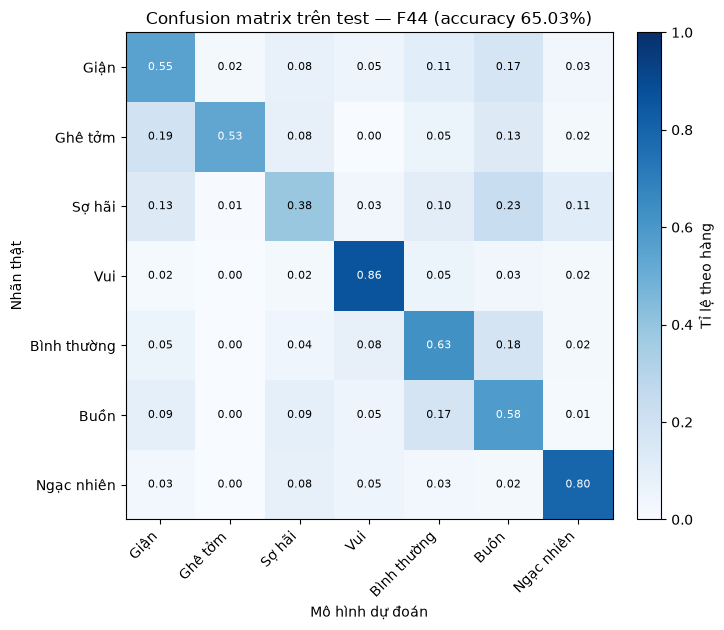

Năm cặp nhầm nhiều nhất:
  Sợ hãi -> Buồn: 23.34%
  Ghê tởm -> Giận: 18.92%
  Bình thường -> Buồn: 17.76%
  Buồn -> Bình thường: 17.24%
  Giận -> Buồn: 16.70%


In [20]:
# Confusion matrix chuẩn hoá theo hàng
cm = confusion_matrix(y_test.numpy(), pred_test, normalize="true")
fig, ax = plt.subplots(figsize=(7.6, 6.4))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(7))
ax.set_xticklabels(TEN_NGAN, rotation=45, ha="right")
ax.set_yticks(range(7))
ax.set_yticklabels(TEN_NGAN)
ax.set_xlabel("Mô hình dự đoán")
ax.set_ylabel("Nhãn thật")
ax.set_title(f"Confusion matrix trên test — {ten_tot} (accuracy {te_acc:.2%})")
for i in range(7):
    for j in range(7):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                color="white" if cm[i, j] > 0.5 else "black", fontsize=8)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Tỉ lệ theo hàng")
plt.tight_layout()
plt.savefig(FIG / "gd4_01_confusion_test.png", dpi=150, bbox_inches="tight")
plt.show()

# Năm cặp nhầm nhiều nhất (bỏ đường chéo)
loi = [(TEN_NGAN[i], TEN_NGAN[j], cm[i, j]) for i in range(7) for j in range(7) if i != j]
print("Năm cặp nhầm nhiều nhất:")
for a, b, v in sorted(loi, key=lambda x: -x[2])[:5]:
    print(f"  {a} -> {b}: {v:.2%}")

### Kết quả và nhận xét

**Ba seed rất ổn định:**

| Seed | Epoch tốt nhất | Val accuracy | Val macro F1 |
|---|---:|---:|---:|
| 42 | 36 / 40 | 0,6555 | 0,6087 |
| 43 | 29 / 37 | 0,6444 | 0,5961 |
| 44 | 37 / 40 | 0,6576 | 0,6138 |
| **Trung bình** | | **0,6525 ± 0,0071** | **0,6062 ± 0,0091** |

Độ lệch chuẩn chỉ 0,7 điểm — chênh lệch giữa các lần chạy không đáng kể so với khoảng cách
giữa các cấu hình ở giai đoạn 3, nên các so sánh trước đó là đáng tin.

**Trên tập test (chỉ chạy một lần, model F44): accuracy 65,03%, macro F1 0,6237.** Cách mốc
world-best của cuộc thi (69% public) khoảng 4 điểm — với một mạng 4 khối tự viết chạy trên CPU,
đây là kết quả hợp lý. Validate của chính F44 là 0,6576 còn test 0,6503, lệch 0,7 điểm theo
hướng thấp hơn, đúng như mong đợi vì test là dữ liệu chưa từng thấy.

So với baseline ở mục 4:

| | Baseline | Mô hình cuối | Chênh |
|---|---:|---:|---:|
| Test accuracy | 0,5237 | **0,6503** | **+12,7 điểm** |
| Macro F1 | 0,4278 | **0,6237** | **+19,6 điểm** |
| Recall lớp Ghê tởm | 0,00 | **0,53** | +0,53 |
| Recall lớp Sợ hãi | 0,23 | 0,38 | +0,15 |

Điều đáng nói nhất là lớp **Ghê tởm**: baseline không đoán đúng một ảnh nào (111 ảnh test), mô
hình cuối đạt recall 0,53 và F1 0,58. Nguyên nhân không phải do class weight — xem phần dưới.

**Về class weight (câu hỏi còn bỏ ngỏ từ nhóm D):** bản `F42_cw` cho val accuracy 0,6371 và
macro F1 0,5869, đều **thấp hơn** seed 42 không có class weight (0,6555 / 0,6087). Như vậy class
weight không có ích ở đây. Lý do có thể là: khi mô hình đã đủ năng lực (4 khối) và có
augmentation, nó tự học được lớp hiếm; ép trọng số chỉ làm mô hình nghiêng về lớp hiếm và mất
độ chính xác ở các lớp phổ biến, kéo F1 trung bình xuống.

**Lớp nào còn yếu:** nhìn confusion matrix, ba lớp dễ lẫn là `Sợ hãi` – `Buồn` – `Bình thường`,
đúng như dự đoán từ phần EDA (ảnh 48×48 quá mờ, ba biểu cảm này khác nhau chủ yếu ở mức độ
nhíu mày và khoé miệng). Năm cặp nhầm nhiều nhất:

| Cặp nhầm | Tỉ lệ |
|---|---:|
| Sợ hãi → Buồn | 23,3% |
| Ghê tởm → Giận | 18,9% |
| Bình thường → Buồn | 17,8% |
| Buồn → Bình thường | 17,2% |
| Giận → Buồn | 16,7% |

Có một điểm thú vị: `Buồn` xuất hiện trong 4/5 cặp nhầm nhiều nhất, nghĩa là "Buồn" đang trở
thành lớp hút — mô hình hay đoán Buồn khi phân vân. Đó cũng là lý do recall của Buồn (0,58) cao
hơn recall Sợ hãi (0,38).

### Tổng kết cả ba giai đoạn: yếu tố nào quan trọng nhất?

| Thay đổi | Ảnh hưởng đo được |
|---|---|
| Tăng ngân sách train 18 → 40 epoch + augmentation | 0,589 → **0,6525** (val), lớn nhất |
| Dung lượng mô hình (2 khối → 4 khối) | 0,330 → 0,589 (ở 18 epoch) |
| Optimizer (Adam/AdamW/SGD) | < 1 điểm |
| Class weight | −1,8 điểm accuracy, −2,2 điểm F1 |
| Dropout 0,5 | −2,0 điểm |

Bài học: với dữ liệu nhỏ và ảnh 48×48, **cho mô hình học đủ lâu** và **làm khó dữ liệu bằng
augmentation** có tác dụng hơn cả việc đổi optimizer hay thêm thủ thuật cân bằng lớp.

Một con số chứng minh rõ nhất: A4 ở 18 epoch có khoảng cách train–validation là **0,324**
(train 0,908 / val 0,589). Cùng kiến trúc đó, thêm augmentation và học 40 epoch, khoảng cách
chỉ còn **0,018** (train 0,675 / val 0,657) — augmentation không làm mô hình yếu đi mà kéo nó
về đúng mức, để phần epoch tăng thêm chuyển thành cải thiện thật.

## 7. Trực quan hoá bộ lọc và bản đồ đặc trưng

Đề bài yêu cầu "visualize the final convolution filters". Phần này xem hai thứ khác nhau:

- **Bộ lọc (filter/kernel)** là *tham số học được* của mô hình: mỗi filter 3×3 là một mẫu nhỏ mà
  mạng dùng để quét ảnh. Nhìn vào đó biết mạng "để ý" hình dạng gì.
- **Bản đồ đặc trưng (feature map)** là *kết quả* khi cho một ảnh cụ thể đi qua lớp đó. Cùng một
  bộ lọc nhưng ảnh khác nhau cho bản đồ khác nhau.

Ta dùng mô hình cuối `F44` đã huấn luyện.

### Bộ lọc lớp tích chập 1

Lớp `Conv2d(1, 32, 3, 3)` có 32 filter, mỗi filter chỉ 3×3 = 9 trọng số vì ảnh đầu vào có 1 kênh.
Ta vẽ từng filter thành ô 3×3, màu đỏ là trọng số dương (làm nổi chi tiết), xanh là âm (dìm
chi tiết). Cùng thang màu cho cả 32 ô để so sánh được với nhau.

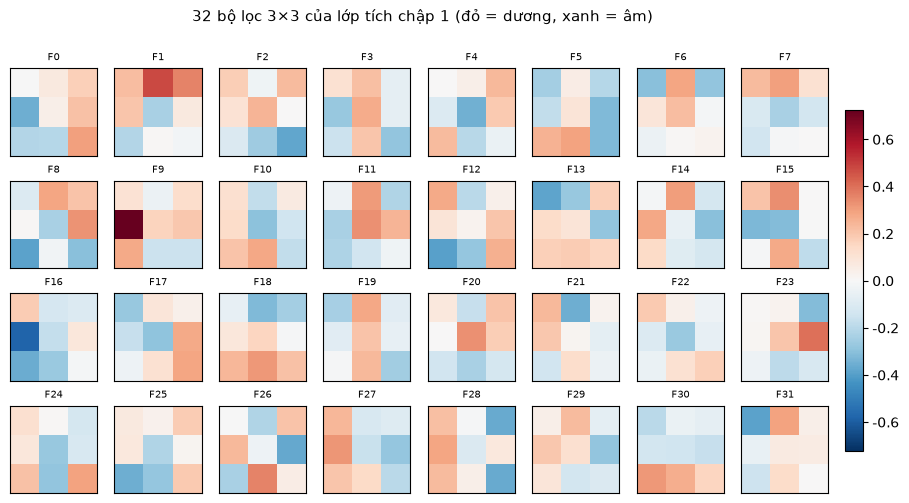

Trọng số conv1: min -0.578 | max 0.724 | trung bình trị tuyệt đối 0.173
Tổng năng lượng theo từng vị trí 3×3 (trung bình 32 filter):
[[0.158 0.179 0.151]
 [0.186 0.187 0.163]
 [0.185 0.182 0.167]]


In [21]:
w1 = model_cuoi.features[0].weight.detach().cpu().squeeze(1)  # (32, 3, 3)
vmax = float(w1.abs().max())

fig, axes = plt.subplots(4, 8, figsize=(11, 5.6))
for i, ax in enumerate(axes.flat):
    ax.imshow(w1[i], cmap="RdBu_r", vmin=-vmax, vmax=vmax, interpolation="nearest")
    ax.set_title(f"F{i}", fontsize=7)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("32 bộ lọc 3×3 của lớp tích chập 1 (đỏ = dương, xanh = âm)", fontsize=11)
fig.colorbar(plt.cm.ScalarMappable(cmap="RdBu_r", norm=plt.Normalize(-vmax, vmax)), ax=axes, fraction=0.02, pad=0.02)
plt.savefig(FIG / "gd5_01_filter_conv1.png", dpi=150, bbox_inches="tight")
plt.show()

# Thống kê nhanh để nhận xét
print(f"Trọng số conv1: min {w1.min():.3f} | max {w1.max():.3f} | trung bình trị tuyệt đối {w1.abs().mean():.3f}")
print(f"Tổng năng lượng theo từng vị trí 3×3 (trung bình 32 filter):")
print(np.round(w1.abs().mean(dim=0).numpy(), 3))

### Bộ lọc lớp tích chập 2 và 3

Hai lớp này có nhiều kênh đầu vào (32 và 128) nên không thể vẽ mỗi filter thành một ảnh màu được.
Cách phổ biến là lấy **trung bình trị tuyệt đối** trên các kênh đầu vào: ô nào sáng nghĩa là filter
đó tập trung vào vị trí không gian đó. Cách này bỏ mất thông tin dấu nhưng vẫn cho biết xu hướng.

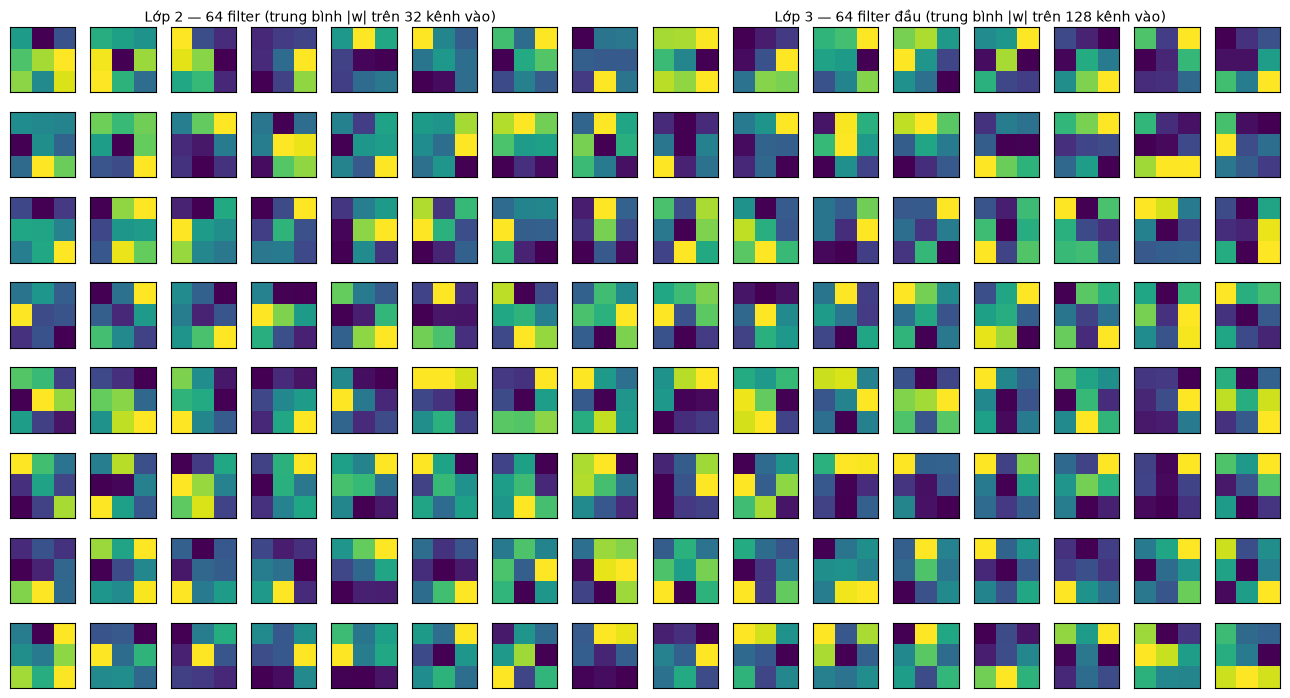

Năng lượng trung bình mỗi filter (lớp 2): 0.0755
Năng lượng trung bình mỗi filter (lớp 3): 0.0748
Số filter lớp 3 có năng lượng > 2 lần trung bình: 0


In [22]:
w2 = model_cuoi.features[4].weight.detach().cpu().abs().mean(1)    # (64, 3, 3)
w3 = model_cuoi.features[8].weight.detach().cpu().abs().mean(1)    # (256, 3, 3)
w3 = w3[:64]                                                       # chỉ vẽ 64 filter đầu

fig, axes = plt.subplots(8, 16, figsize=(13, 7))
for i, ax in enumerate(axes[:, :8].flat):
    ax.imshow(w2[i], cmap="viridis", interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks([])
for i, ax in enumerate(axes[:, 8:].flat):
    ax.imshow(w3[i], cmap="viridis", interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks([])
fig.text(0.25, 0.98, "Lớp 2 — 64 filter (trung bình |w| trên 32 kênh vào)", ha="center", fontsize=10)
fig.text(0.75, 0.98, "Lớp 3 — 64 filter đầu (trung bình |w| trên 128 kênh vào)", ha="center", fontsize=10)
plt.tight_layout()
plt.savefig(FIG / "gd5_02_filter_conv23.png", dpi=150, bbox_inches="tight")
plt.show()

print("Năng lượng trung bình mỗi filter (lớp 2):", round(float(w2.mean()), 4))
print("Năng lượng trung bình mỗi filter (lớp 3):", round(float(w3.mean()), 4))
print("Số filter lớp 3 có năng lượng > 2 lần trung bình:", int((w3.mean(dim=(1, 2)) > 2 * w3.mean()).sum()))

### Bản đồ đặc trưng của một ảnh cụ thể

Ta lấy một ảnh "Vui" và một ảnh "Sợ hãi" trong tập test, cho đi qua từng lớp và vẽ 8 bản đồ đặc
trưng đầu tiên của lớp 1, 2, 3. Ảnh càng vào sâu thì bản đồ càng nhỏ (48×48 → 24×24 → 12×12) nhưng
số lượng tăng lên, đó chính là ý tưởng "đổi độ phân giải lấy số kênh".

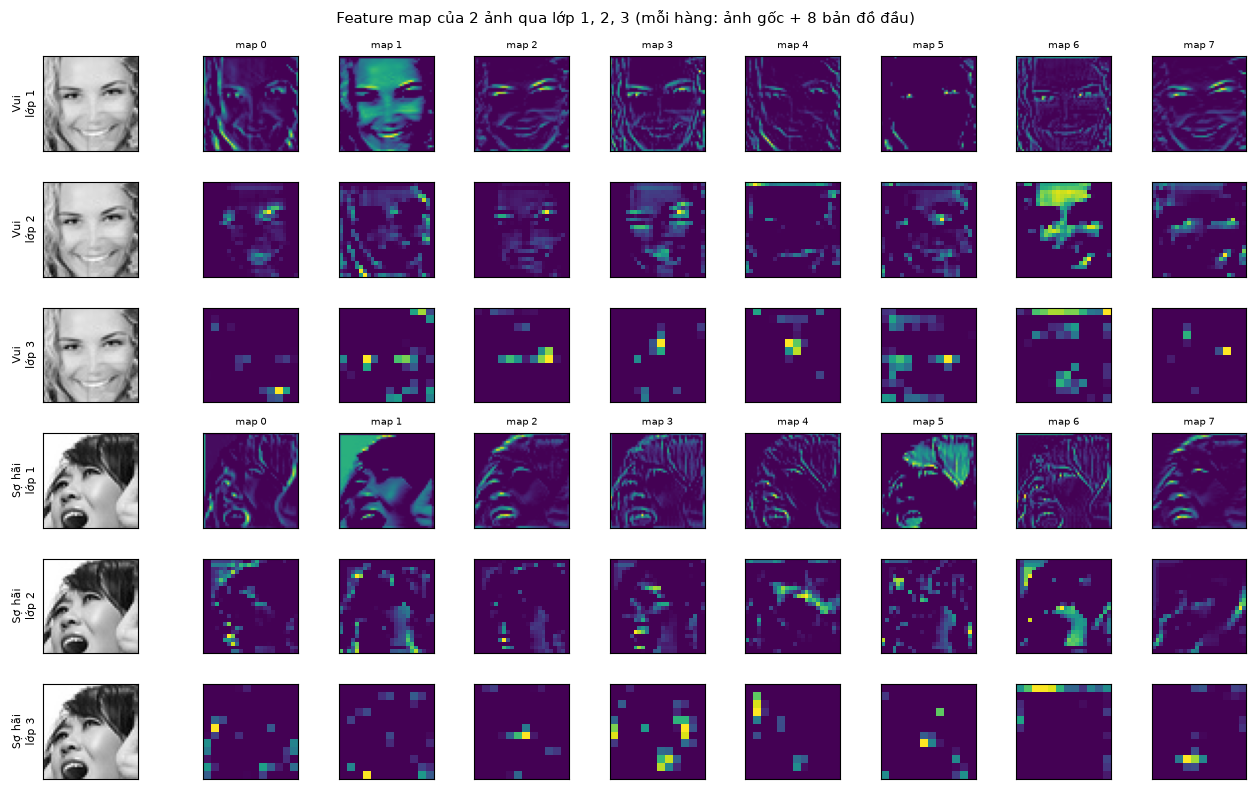

In [23]:
i_vui = int((y_test == CLASSES.index("happy")).nonzero()[0])
i_so = int((y_test == CLASSES.index("fear")).nonzero()[0])

def ban_do(i):
    """Chạy ảnh thứ i qua 3 lớp đầu, trả về bản đồ đặc trưng sau ReLU."""
    x = to_batch(X_test[i : i + 1])
    a1 = model_cuoi.features[:3](x)
    a2 = model_cuoi.features[:7](x)
    a3 = model_cuoi.features[:11](x)
    return [a1, a2, a3]

fig, axes = plt.subplots(6, 9, figsize=(13, 8), gridspec_kw={"width_ratios": [1.4] + [1] * 8})
for hang, (i, ten) in enumerate([(i_vui, "Vui"), (i_so, "Sợ hãi")]):
    for lop, a in enumerate(ban_do(i)):
        r = hang * 3 + lop
        ax = axes[r, 0]
        ax.imshow(X_test[i], cmap="gray")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_ylabel(f"{ten}\nlớp {lop + 1}", fontsize=8)
        for k in range(8):
            axk = axes[r, k + 1]
            axk.imshow(a[0, k].detach(), cmap="viridis")
            axk.set_xticks([])
            axk.set_yticks([])
            if lop == 0:
                axk.set_title(f"map {k}", fontsize=7)
plt.suptitle("Feature map của 2 ảnh qua lớp 1, 2, 3 (mỗi hàng: ảnh gốc + 8 bản đồ đầu)", fontsize=11)
plt.tight_layout()
plt.savefig(FIG / "gd5_03_feature_maps.png", dpi=150, bbox_inches="tight")
plt.show()

### Nhận xét

**Lớp 1.** 32 filter chỉ có 9 trọng số mỗi cái, trải trong khoảng −0,58 đến 0,72, trị tuyệt đối
trung bình 0,173. Năng lượng theo 8 vị trí của ô 3×3 gần như bằng nhau (0,15–0,19), nghĩa là không
filter nào "khoanh vùng" một góc cụ thể — chúng đều đang so sánh cường độ sáng giữa các điểm lân
cận. Nhìn hình thấy hai kiểu rõ rệt:

- Phần lớn có **hai vùng đối lập** (nửa này đỏ, nửa kia xanh) như F6, F10, F15, F24 — đây là bộ dò
  cạnh theo hướng, tương đương Sobel dọc/ngang. Với ảnh mặt, loại này bắt lông mày, viền mắt, khoé
  miệng.
- Một số dồn gần hết trọng số vào **một điểm** (F9, F16, F31) — bộ dò điểm sáng/tối cục bộ, kiểu
  "quanh đây có đốm tối không".

**Lớp 2 và 3.** Năng lượng trung bình của hai lớp gần như trùng nhau (0,0755 và 0,0748) và
**không filter nào vượt 2 lần mức trung bình** — tức mạng không dành riêng một nhóm filter "chuyên
gia", mà phân bố đều. Dù đã lấy trung bình trên 32/128 kênh, hình vẫn cho thấy các mẫu một phía
sáng một phía tối, tức lớp sâu vẫn làm việc so sánh cường độ, chỉ khác là tổng hợp trên nhiều kênh
đầu vào chứ không còn trên điểm ảnh gốc.

**Bản đồ đặc trưng.** Mức trừu tượng tăng dần rất rõ:

- Lớp 1 (48×48): vẫn nhận ra khuôn mặt — map 1, 4, 7 sáng đúng vùng mắt và miệng.
- Lớp 2 (24×24): chỉ còn các đốm sáng ở mắt, lỗ mũi, khoé miệng.
- Lớp 3 (12×12): gần như không còn hình dạng, chỉ là vài ô sáng rời rạc, trong khi số kênh tăng
  từ 32 lên 128. Đây chính là "đổi độ phân giải lấy số kênh".

So hai ảnh: ảnh **Vui** kích hoạt mạnh vùng má và khoé miệng (map 1 và 7 ở lớp 1), còn ảnh
**Sợ hãi** kích hoạt vùng mắt và vùng miệng mở rộng hơn. Cùng một filter nhưng hai ảnh cho bản đồ
khác nhau — đó là cơ sở để lớp phân loại cuối tách được hai biểu cảm, dù với ảnh 48×48 khác biệt
này còn mong manh, khớp với việc mô hình vẫn nhầm Sợ hãi thành Buồn 23% số lần.
